
# Dados

Os dados das séries temporais necessárias para o desenvolvimento do artigo foram obtidos através da Agência Nacional de Águas, sendo disponibilizados de forma pública na aplicação Hidroweb. 

- https://www.snirh.gov.br/hidroweb/serieshistoricas
- Preenchimento com o código e download do dataset contendo as séries de acordo com o tipo da estação.
- Código da estação de Humaitá **15630000**

# Cota
Os dados são referentes ao período entre **Março de 1931 até Março de 2026**. 
As linhas do dataset representam os registros referentes ao intervalo fechado de um mês.
As colunas do dataset expõem informações fundamentais para a compreensão da natureza dos dados e sua forma de representação e são detalhadas à seguir:

# Nível de consistência

A primeira coluna é relativa ao nível de consistência dos dados, sendo representado de forma binária por 1 e 2, sendo 1 o indicativo de dados brutos e 2 o indicativo de dados tratados mediante análise especializada. A análise especializada naturalmente ocorre de forma posterior à disponibilização dos dados brutos, sendo que para o grau 2, nós temos dados disponíveis até o final de 2023. A série representada nos anos seguintes é integralmente composta por valores brutos.

# Data
A coluna trata da data de início dos registros daquele mês, sendo representada pelo primeiro dia do referido mês

# Hora
Trata do horário em que as medições foram realizadas, podendo ser representadas em 7h, 17h e sem hora informada. Os registros que indicam médias de medição não têm hora declada.

# Média Diária
Informa se o registro é resultado de uma média diária ou de uma amostra de medição. A maioria dos registros é formada por média diária. A coluna apresenta somente valores de 0 e 1 para indicar o uso de média diária.

# Tipo de medição
Informa o método de medição, que no referido dataset é utilizada a medição por escala, exceto por um único registro, o qual foi medido através de Data logger

# Tipo de registros escolhidos
Com a intenção de se utilizar para o trabalho dados com maior completude, confiabilidade e menor número de ruído, foi escolhido o subconjunto de dados em que o nível de consistência é 2, ou seja, passaram por análise especializada do órgão. tais dados estão presentes no intervalo entre Março de 1931 até Dezembro de 2023. Todos os registros nessa consistência são formados por médias diárias, e não por valores diretamente coletados por sensores. No entanto, percebeu-se que entre os anos de 1949 e 1967 existe uma lacuna de dados que não foi exposta no dataset. Devido à essa ausência significativa e a iminente descaracterização da série, optou-se por utilizar os dados a partir de 1967 até 2023, onde não há nenhum registro de dado ausente.


Os dados de cota eram apresentados no formato largo, e foram transformados em formato longo para facilitar o processo de análise e treinamento

# Gaps de dados
percebemos que existe um gap de dados entre 1949 e 1967, além de outro gap de 5 meses entre 01/06/1990 e 01/11/1990. Com o objetivo de alinhar a sazonalidade anual do dataset com o início de um ciclo até o final de outro, foi definida a data de início em 01/01/1991 e a data final como 31/12/2023.

entre 01/04/2014 e 01/05/2014 foram encontrados 21 registros faltantes. Foi verificado preencher tais registros através da utilização dos dados da estação UHE Santo Antonio que também fica em humaitá e está correlacionada com a dinâmica da estação principal, o que foi provado pela observação sobreposta de dados entre 01/06/2014 e 20/06/2014 para as duas estações, sendo este o intervalo do mês conseguinte aos dois meses que apresentaram dados faltantes.

OBS: O status 3 é encontrado para a maior parte dos dados medidos na estação de santo antonio. o status corresponde uma medição duvidosa, o que não invalida a escolha para a inserção dos dados faltantes devido ao caráter de correlação clara entre as estações. A escolha é superior à utilização de simples interpolação linear, o que descaracterizaria a dinâmica da curva de cota ao longo dos intervalos para inputação de valores genéricos.

A primeira janela vai de 15/04/2014 a 30/04/2014 (16 dias consecutivos).
A segunda janela vai de 12/05/2014 a 16/05/2014 (5 dias consecutivos).




In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn statsmodels "timesfm[mlx]"


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Requirements

In [3]:
import os
import time
import platform
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import seasonal_decompose
import seaborn as sns
%pip install pandas numpy matplotlib seaborn scikit-learn statsmodels "timesfm[mlx]"
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

warnings.filterwarnings("ignore")


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Dados

Os dados das séries temporais necessárias para o desenvolvimento do artigo foram obtidos através da Agência Nacional de Águas, sendo disponibilizados de forma pública na aplicação Hidroweb. 

- https://www.snirh.gov.br/hidroweb/serieshistoricas
- Preenchimento com o código e download do dataset contendo as séries de acordo com o tipo da estação.
- Código da estação de Humaitá **15630000**

# Cota
Os dados são referentes ao período entre **Março de 1931 até Março de 2026**. 
As linhas do dataset representam os registros referentes ao intervalo fechado de um mês.
As colunas do dataset expõem informações fundamentais para a compreensão da natureza dos dados e sua forma de representação e são detalhadas à seguir:

In [ ]:
humaita_data = pd.read_csv('data/humaita/15630000_Cotas.csv', sep=';', encoding='utf-8', header=11,low_memory=False)
humaita_data.head()

,EstacaoCodigo,NivelConsistencia,Data,hora,MediaDiaria,TipoMedicaoCotas,Maxima,Minima,Media,DiaMaxima,...,Cota22Status,Cota23Status,Cota24Status,Cota25Status,Cota26Status,Cota27Status,Cota28Status,Cota29Status,Cota30Status,Cota31Status
0,15940000,1,01/06/2026,07:00,0,1,1922.0,1861.0,1893.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
1,15940000,1,01/06/2026,17:00,0,1,1922.0,1861.0,1893.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2,15940000,1,01/06/2026,NaN,1,1,1922.0,1861.0,1893.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
3,15940000,1,01/05/2026,07:00,0,1,1948.0,1921.0,1936.0,8.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,15940000,1,01/05/2026,17:00,0,1,1948.0,1921.0,1936.0,8.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [5]:
humaita_data.tail()

,EstacaoCodigo,NivelConsistencia,Data,hora,MediaDiaria,TipoMedicaoCotas,Maxima,Minima,Media,DiaMaxima,...,Cota22Status,Cota23Status,Cota24Status,Cota25Status,Cota26Status,Cota27Status,Cota28Status,Cota29Status,Cota30Status,Cota31Status
1429,15940000,1,01/10/1994,07:00,0,1,1338.0,1112.0,1213.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1430,15940000,1,01/10/1994,17:00,0,1,1338.0,1112.0,1213.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1431,15940000,1,01/10/1994,NaN,1,1,1336.0,1115.0,1213.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1432,15940000,1,01/09/1994,17:00,0,1,NaN,NaN,NaN,NaN,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
1433,15940000,1,01/09/1994,07:00,0,1,NaN,NaN,NaN,NaN,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0


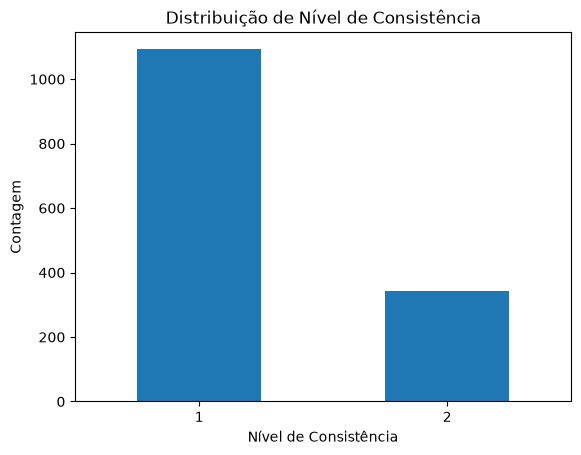

NivelConsistencia
1    1092
2     342
Name: count, dtype: int64


In [6]:
humaita_data['NivelConsistencia'].value_counts().plot(kind='bar')
plt.title('Distribuição de Nível de Consistência')
plt.xlabel('Nível de Consistência')
plt.ylabel('Contagem')
plt.xticks(rotation=0)
plt.show()
print(humaita_data['NivelConsistencia'].value_counts(dropna=False))

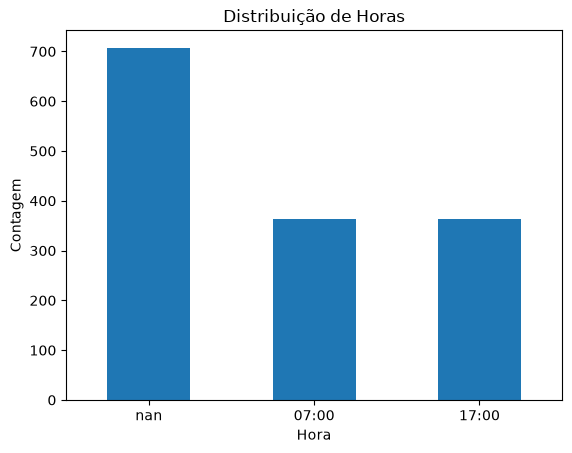

hora
NaN      707
07:00    364
17:00    363
Name: count, dtype: int64


In [7]:
humaita_data['hora'].value_counts(dropna=False).plot(kind='bar')
plt.title('Distribuição de Horas')
plt.xlabel('Hora')
plt.ylabel('Contagem')
plt.xticks(rotation=0)
plt.show()
print(humaita_data['hora'].value_counts(dropna=False))

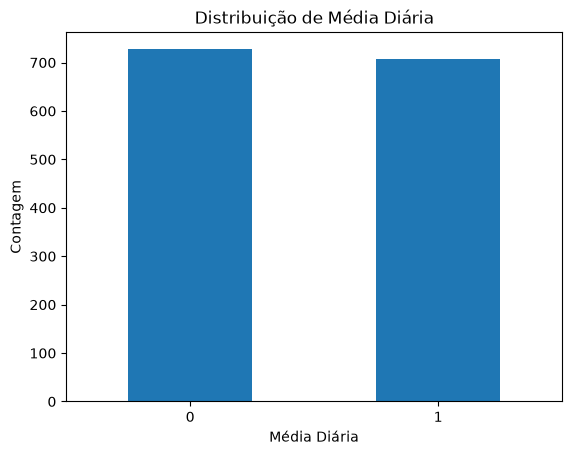

MediaDiaria
0    727
1    707
Name: count, dtype: int64


In [8]:
humaita_data['MediaDiaria'].value_counts(dropna=False).plot(kind='bar')
plt.title('Distribuição de Média Diária')
plt.xlabel('Média Diária')
plt.ylabel('Contagem')
plt.xticks(rotation=0)
plt.show()
print(humaita_data['MediaDiaria'].value_counts())

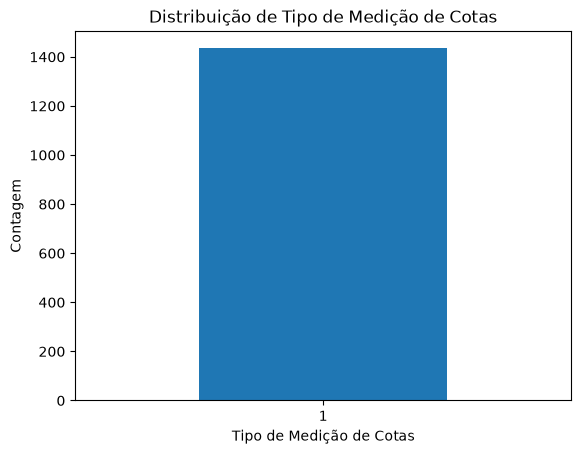

TipoMedicaoCotas
1    1434
Name: count, dtype: int64


In [9]:
humaita_data['TipoMedicaoCotas'].value_counts(dropna=False).plot(kind='bar')
plt.title('Distribuição de Tipo de Medição de Cotas')
plt.xlabel('Tipo de Medição de Cotas')
plt.ylabel('Contagem')
plt.xticks(rotation=0)
plt.show()
print(humaita_data['TipoMedicaoCotas'].value_counts(dropna=False))

In [10]:
river_stage_columns = ["Cota" + f"{x:02d}" for x in range(1, 32)]
river_stage_columns

['Cota01',
 'Cota02',
 'Cota03',
 'Cota04',
 'Cota05',
 'Cota06',
 'Cota07',
 'Cota08',
 'Cota09',
 'Cota10',
 'Cota11',
 'Cota12',
 'Cota13',
 'Cota14',
 'Cota15',
 'Cota16',
 'Cota17',
 'Cota18',
 'Cota19',
 'Cota20',
 'Cota21',
 'Cota22',
 'Cota23',
 'Cota24',
 'Cota25',
 'Cota26',
 'Cota27',
 'Cota28',
 'Cota29',
 'Cota30',
 'Cota31']

In [11]:
river_stage_columns_status = [x + "Status" for x in river_stage_columns]
river_stage_columns_status

['Cota01Status',
 'Cota02Status',
 'Cota03Status',
 'Cota04Status',
 'Cota05Status',
 'Cota06Status',
 'Cota07Status',
 'Cota08Status',
 'Cota09Status',
 'Cota10Status',
 'Cota11Status',
 'Cota12Status',
 'Cota13Status',
 'Cota14Status',
 'Cota15Status',
 'Cota16Status',
 'Cota17Status',
 'Cota18Status',
 'Cota19Status',
 'Cota20Status',
 'Cota21Status',
 'Cota22Status',
 'Cota23Status',
 'Cota24Status',
 'Cota25Status',
 'Cota26Status',
 'Cota27Status',
 'Cota28Status',
 'Cota29Status',
 'Cota30Status',
 'Cota31Status']

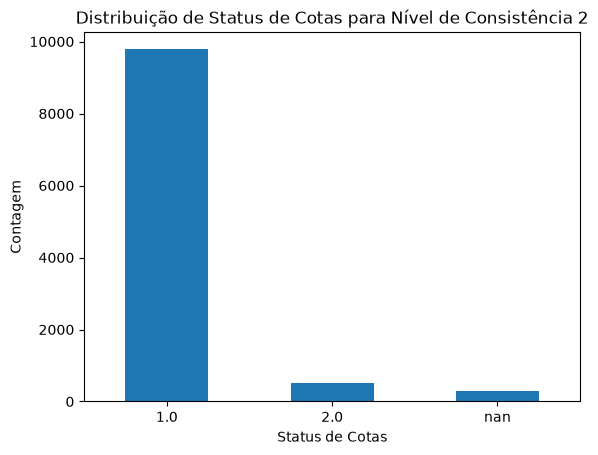

1.0    9779
2.0     525
NaN     298
Name: count, dtype: int64


In [12]:
items = (
    humaita_data.loc[humaita_data['NivelConsistencia'] == 2, river_stage_columns_status]
    .values.flatten()
    .tolist()
)

pd.Series(items).value_counts(dropna=False).plot(kind='bar')
plt.title('Distribuição de Status de Cotas para Nível de Consistência 2')
plt.xlabel('Status de Cotas')
plt.ylabel('Contagem')
plt.xticks(rotation=0)
plt.show()
print(pd.Series(items).value_counts(dropna=False))

In [13]:
# 1. Filter only consistent data
def filter_consistent_data(df):
    filtered_df = df[df["NivelConsistencia"] == 2].copy()

    # 2. Reshape dataframe from wide format to long format
    melted_df = pd.melt(
        filtered_df,
        id_vars=["Data"],
        value_vars=river_stage_columns,
        var_name="day_column",
        value_name="river_stage",
    )

    # 3. Extract the numeric day from the column name (e.g., 'Cota01' -> 1)
    melted_df["day"] = melted_df["day_column"].str.extract(r"(\d+)").astype(int)

    # 4. Parse the reference month and year from the 'Data' column
    melted_df["ref_date"] = pd.to_datetime(
        melted_df["Data"], format="%d/%m/%Y", errors="coerce"
    )
    melted_df["year"] = melted_df["ref_date"].dt.year
    melted_df["month"] = melted_df["ref_date"].dt.month

    # 5. Construct the full date timestamp
    # 'errors="coerce"' automatically converts invalid calendar dates (e.g., Feb 31st) to NaT/NaN
    melted_df["date"] = pd.to_datetime(
        {
            "year": melted_df["year"],
            "month": melted_df["month"],
            "day": melted_df["day"],
        },
        errors="coerce",
    )

    # 6. Identify invalid records (missing values, or invalid dates)
    invalid_records = melted_df["river_stage"].isna() | melted_df["date"].isna()

    # Optional: Print summary of skipped records
    print(f"Skipped invalid records: {invalid_records.sum()} of {len(melted_df)}")

    # 7. Keep valid records, sort chronologically, and reset index
    river_stage_data = (
        melted_df.loc[~invalid_records, ["date", "river_stage"]]
        .sort_values("date")
        .reset_index(drop=True)
    )

    return river_stage_data

In [15]:
humaita_river_stage_data = filter_consistent_data(humaita_data)
humaita_river_stage_data

Skipped invalid records: 298 of 10602


,date,river_stage
0,1994-10-01,1336.0
1,1994-10-02,1326.0
2,1994-10-03,1315.0
3,1994-10-04,1303.0
4,1994-10-05,1292.0
...,...,...
10299,2023-12-27,1045.0
10300,2023-12-28,1054.0
10301,2023-12-29,1060.0
10302,2023-12-30,1066.0


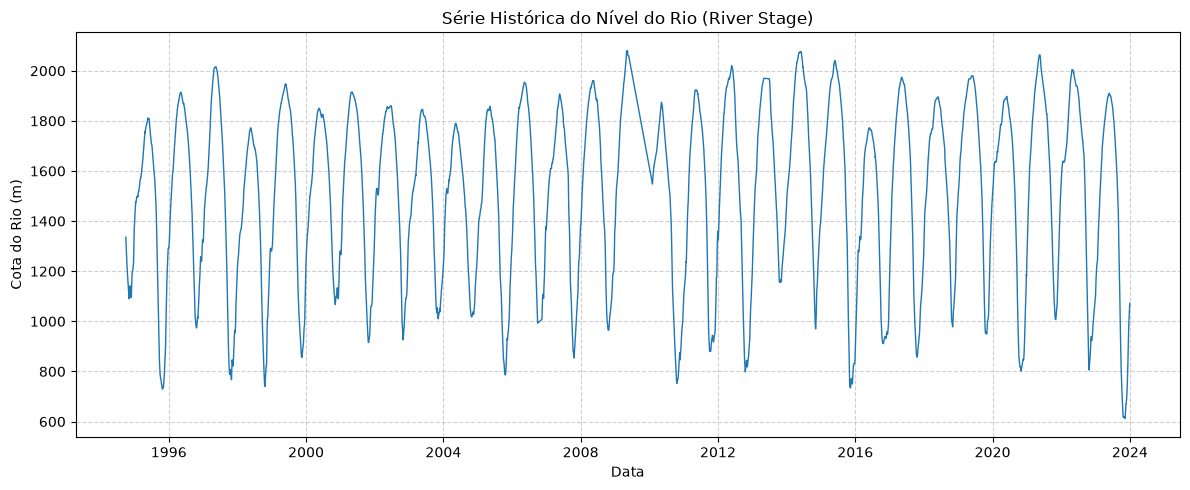

In [16]:
humaita_river_stage_data["date"] = pd.to_datetime(humaita_river_stage_data["date"])

# Plota a série
plt.figure(figsize=(12, 5))
plt.plot(
    humaita_river_stage_data["date"],
    humaita_river_stage_data["river_stage"],
    color="#1f77b4",
    linewidth=1,
)

plt.title("Série Histórica do Nível do Rio (River Stage)")
plt.xlabel("Data")
plt.ylabel("Cota do Rio (m)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [17]:
humaita_river_stage_data = humaita_river_stage_data[humaita_river_stage_data['date'] >= "1991-01-01"]

In [18]:
def get_missing_dates(df, start_date, end_date):
    expected_dates = pd.date_range(start=start_date, end=end_date, freq="D")
    actual_dates = df["date"]
    missing_dates = expected_dates.difference(actual_dates)
    return missing_dates

In [20]:
start_date = "1995-01-01"
end_date = "2023-12-31"

missing_humaita_dates = get_missing_dates(humaita_river_stage_data, start_date, end_date)
print(missing_humaita_dates.empty)
print(missing_humaita_dates, len(missing_humaita_dates))

False
DatetimeIndex(['2006-10-01', '2006-10-02', '2006-10-03', '2006-10-04',
               '2006-10-05', '2006-10-06', '2006-10-07', '2006-10-08',
               '2006-10-09', '2006-10-10',
               ...
               '2021-08-22', '2021-08-23', '2021-08-24', '2021-08-25',
               '2021-08-26', '2021-08-27', '2021-08-28', '2021-08-29',
               '2021-08-30', '2021-08-31'],
              dtype='datetime64[us]', length=380, freq=None) 380


In [18]:
santo_antonio_data = pd.read_csv('data/santo_antonio/15629000_Cotas.csv', sep=';', encoding='utf-8', header=11,low_memory=False)

santo_antonio_river_stage_data = filter_consistent_data(santo_antonio_data)
print(set(missing_humaita_dates).issubset(santo_antonio_river_stage_data['date']))
print(missing_humaita_dates.difference(santo_antonio_river_stage_data['date']))
print(missing_humaita_dates.intersection(santo_antonio_river_stage_data['date']))

Skipped invalid records: 91 of 3317
False
DatetimeIndex(['2014-05-12', '2014-05-13', '2014-05-14', '2014-05-15',
               '2014-05-16'],
              dtype='datetime64[us]', freq=None)
DatetimeIndex(['2014-04-15', '2014-04-16', '2014-04-17', '2014-04-18',
               '2014-04-19', '2014-04-20', '2014-04-21', '2014-04-22',
               '2014-04-23', '2014-04-24', '2014-04-25', '2014-04-26',
               '2014-04-27', '2014-04-28', '2014-04-29', '2014-04-30'],
              dtype='datetime64[us]', freq='D')


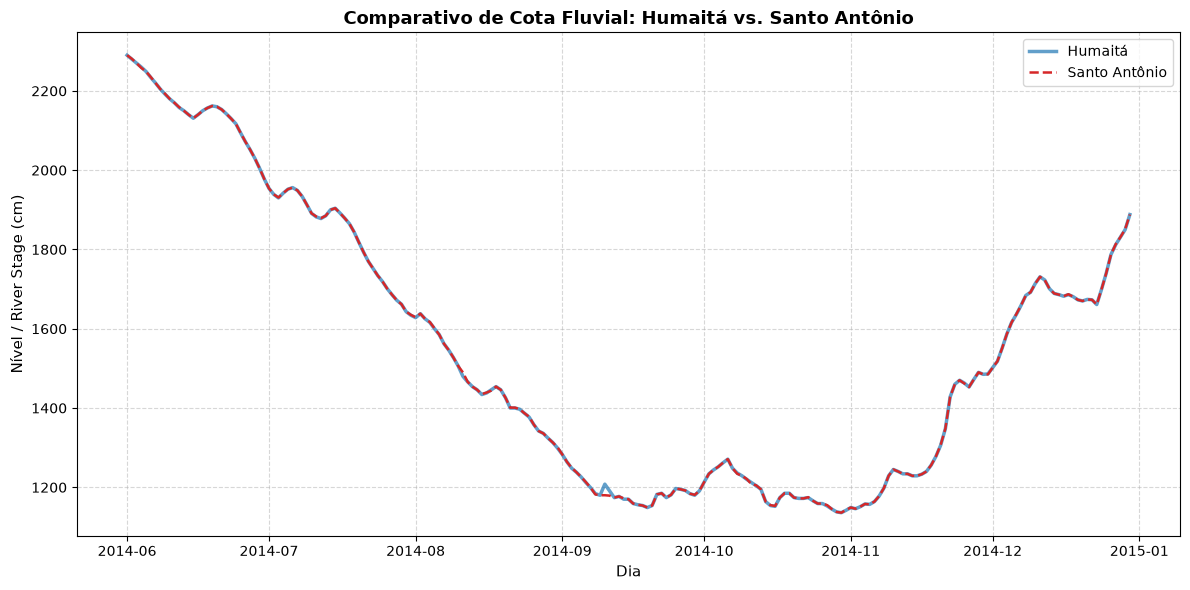

In [19]:
initial_date = '2014-06-01'
end_date = '2014-12-30'

santo_antonio = santo_antonio_river_stage_data[
    (santo_antonio_river_stage_data['date'] >= initial_date) &
    (santo_antonio_river_stage_data['date'] <= end_date)
]

humaita = humaita_river_stage_data[
    (humaita_river_stage_data['date'] >= initial_date) &
    (humaita_river_stage_data['date'] <= end_date)
] 

# Criação da figura
plt.figure(figsize=(12, 6), dpi=100)

# Plota Humaitá (linha azul sólida mais espessa)
plt.plot(
    humaita["date"],
    humaita["river_stage"],
    label="Humaitá",
    color="#1f77b4",
    linewidth=2.5,
    alpha=0.7,
)

# Plota Santo Antônio (linha vermelha tracejada por cima para destacar as pequenas variações)
plt.plot(
    santo_antonio["date"],
    santo_antonio["river_stage"],
    label="Santo Antônio",
    color="#d62728",
    linewidth=1.8,
    linestyle="--",
)

# Rótulos e estilização
plt.title(
    "Comparativo de Cota Fluvial: Humaitá vs. Santo Antônio",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Dia", fontsize=11)
plt.ylabel("Nível / River Stage (cm)", fontsize=11)

plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()

plt.show()

In [20]:
for date in missing_humaita_dates:
    value = santo_antonio_river_stage_data.loc[santo_antonio_river_stage_data['date'] == date, 'river_stage']

    if value.empty:
        print(date)
        humaita_river_stage_data.loc[len(humaita_river_stage_data)] = {'date': date, 'river_stage': None}
    else:
        humaita_river_stage_data.loc[len(humaita_river_stage_data)] = {'date': date, 'river_stage': value.values[0]}

2014-05-12 00:00:00
2014-05-13 00:00:00
2014-05-14 00:00:00
2014-05-15 00:00:00
2014-05-16 00:00:00


In [21]:
start_date = "1991-01-01"
end_date = "2023-12-31"

missing_humaita_dates = get_missing_dates(humaita_river_stage_data, start_date, end_date)
print(missing_humaita_dates.empty)
print(missing_humaita_dates, len(missing_humaita_dates))

True
DatetimeIndex([], dtype='datetime64[us]', freq='D') 0


In [22]:
humaita_river_stage_data.isna().sum()

date           0
river_stage    5
dtype: int64

In [23]:
humaita_river_stage_data

,date,river_stage
15042,1991-01-01,1590.0
15043,1991-01-02,1574.0
15044,1991-01-03,1576.0
15045,1991-01-04,1589.0
15046,1991-01-05,1598.0
...,...,...
12048,2014-05-12,None
12049,2014-05-13,None
12050,2014-05-14,None
12051,2014-05-15,None


In [24]:
humaita_river_stage_data = humaita_river_stage_data.sort_values("date").reset_index(drop=True)

humaita_river_stage_data["river_stage"] = pd.to_numeric(
    humaita_river_stage_data["river_stage"],
    errors="coerce",
)

humaita_river_stage_data["river_stage"] = (
    humaita_river_stage_data["river_stage"]
    .interpolate(method="linear", limit_area="inside")
)

In [25]:
duplicadas = humaita_river_stage_data["date"].duplicated().sum()
print("\nDatas duplicadas:", duplicadas)


Datas duplicadas: 0


In [26]:
# ============================================
# PARTE 2 — ESTATÍSTICA DESCRITIVA
# ============================================

print("=" * 60)
print("ESTATÍSTICA DESCRITIVA")
print("=" * 60)


# Estatísticas principais

estatisticas = humaita_river_stage_data["river_stage"].describe()

print(estatisticas)


# --------------------------------------------
# ESTATÍSTICAS ADICIONAIS
# --------------------------------------------

media = humaita_river_stage_data["river_stage"].mean()
mediana = humaita_river_stage_data["river_stage"].median()
desvio = humaita_river_stage_data["river_stage"].std()

coef_variacao = desvio / media * 100

print("\nMédia:", media)
print("Mediana:", mediana)
print("Desvio padrão:", desvio)
print("Coeficiente de variação:", coef_variacao, "%")


# --------------------------------------------
# ASSIMETRIA E CURTOSE
# --------------------------------------------

print("\nAssimetria:", humaita_river_stage_data["river_stage"].skew())
print("Curtose:", humaita_river_stage_data["river_stage"].kurtosis())

ESTATÍSTICA DESCRITIVA
count    12053.000000
mean      1646.411391
std        454.331707
min        894.000000
25%       1204.000000
50%       1655.000000
75%       2067.000000
max       2563.000000
Name: river_stage, dtype: float64

Média: 1646.4113913548495
Mediana: 1655.0
Desvio padrão: 454.3317065937823
Coeficiente de variação: 27.59527229825031 %

Assimetria: 0.014159773524740205
Curtose: -1.3839355448130994


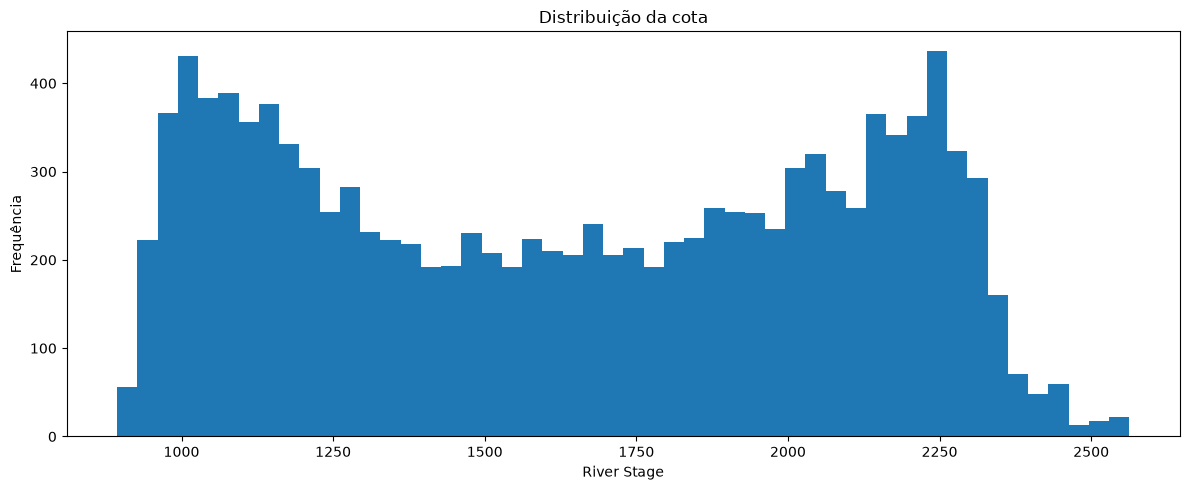

In [27]:
# --------------------------------------------
# HISTOGRAMA
# --------------------------------------------

plt.figure(figsize=(12, 5))

plt.hist(
    humaita_river_stage_data["river_stage"],
    bins=50
)

plt.xlabel("River Stage")
plt.ylabel("Frequência")
plt.title("Distribuição da cota")

plt.tight_layout()
plt.show()

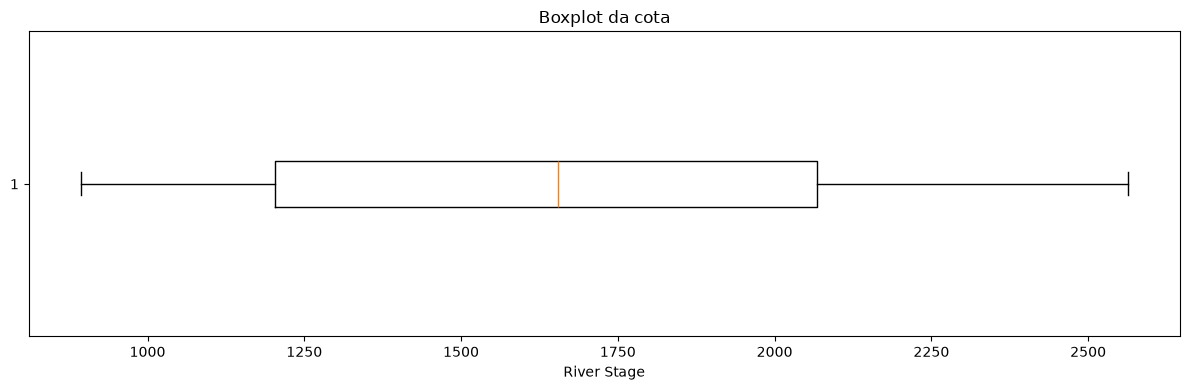

In [28]:
# --------------------------------------------
# BOXPLOT
# --------------------------------------------

plt.figure(figsize=(12, 4))

plt.boxplot(
    humaita_river_stage_data["river_stage"],
    vert=False
)

plt.xlabel("River Stage")
plt.title("Boxplot da cota")

plt.tight_layout()
plt.show()

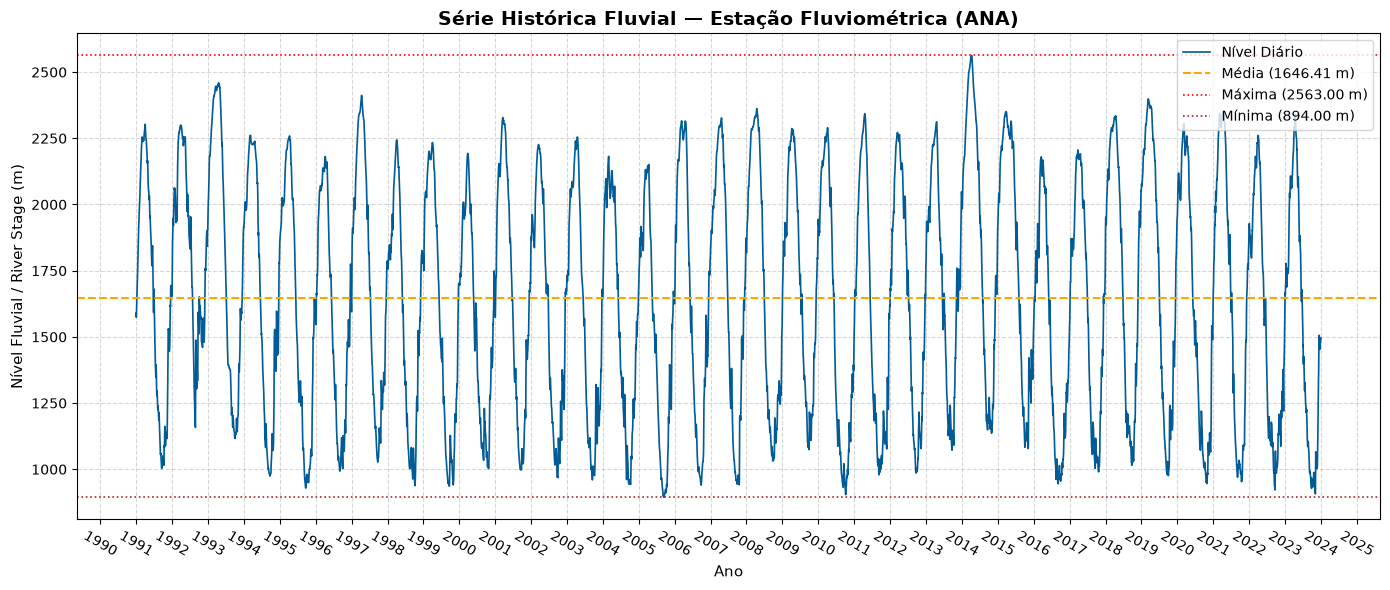

In [29]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(14, 6), dpi=100)

# Linha principal da cota
plt.plot(
    humaita_river_stage_data["date"],
    humaita_river_stage_data["river_stage"],
    color="#005b96",
    linewidth=1.2,
    label="Nível Diário",
)

# Estatísticas para linhas de referência
mean_stage = humaita_river_stage_data["river_stage"].mean()
max_stage = humaita_river_stage_data["river_stage"].max()
min_stage = humaita_river_stage_data["river_stage"].min()

# Linhas horizontais de referência
plt.axhline(
    y=mean_stage,
    color="orange",
    linestyle="--",
    linewidth=1.5,
    label=f"Média ({mean_stage:.2f} m)",
)
plt.axhline(
    y=max_stage,
    color="red",
    linestyle=":",
    linewidth=1.2,
    label=f"Máxima ({max_stage:.2f} m)",
)
plt.axhline(
    y=min_stage,
    color="brown",
    linestyle=":",
    linewidth=1.2,
    label=f"Mínima ({min_stage:.2f} m)",
)

# Formatação do Eixo X (Datas)
ax = plt.gca()
ax.xaxis.set_major_locator(
    mdates.YearLocator()
)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.xticks(rotation=-30)

# Rótulos e Título
plt.title("Série Histórica Fluvial — Estação Fluviométrica (ANA)", fontsize=14, fontweight="bold")
plt.xlabel("Ano", fontsize=11)
plt.ylabel("Nível Fluvial / River Stage (m)", fontsize=11)

plt.legend(loc="upper right", frameon=True)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

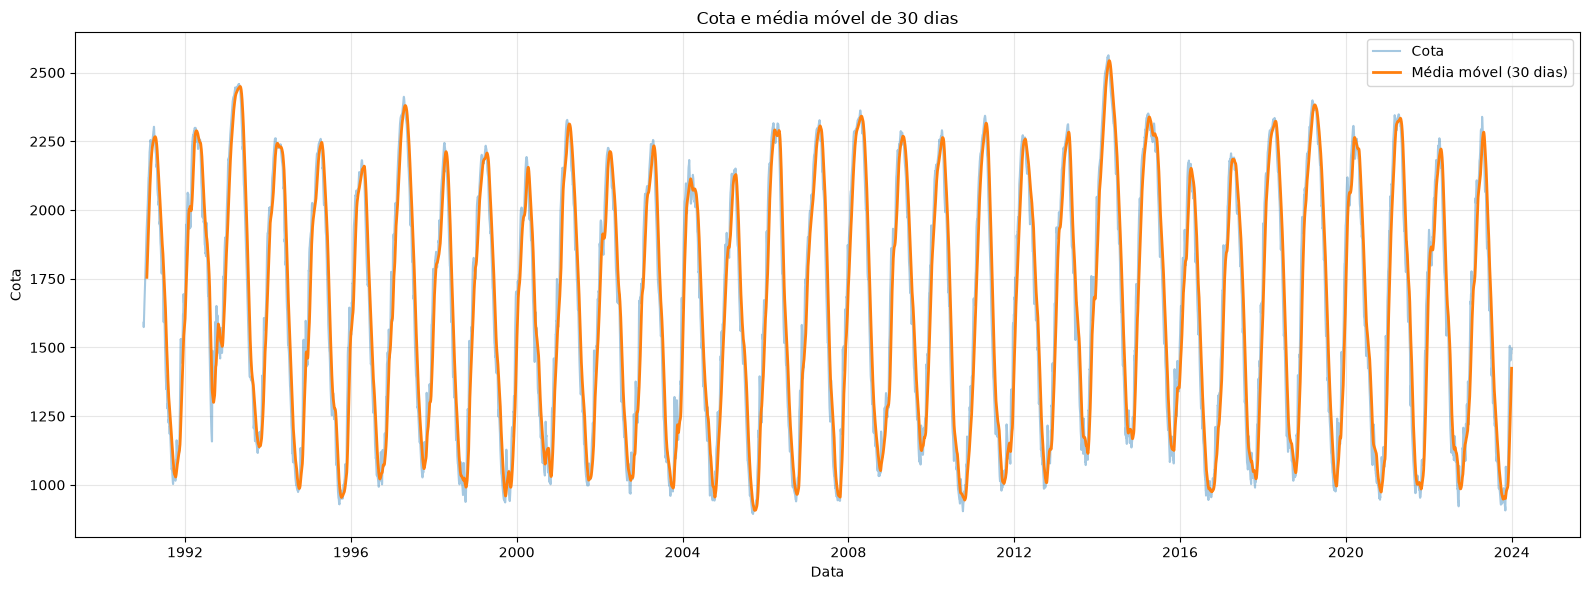

In [30]:
# --------------------------------------------
# MÉDIA MÓVEL
# --------------------------------------------

humaita_river_stage_data["rolling_30"] = (
    humaita_river_stage_data["river_stage"]
    .rolling(30)
    .mean()
)

plt.figure(figsize=(16, 6))

plt.plot(
    humaita_river_stage_data["date"],
    humaita_river_stage_data["river_stage"],
    alpha=0.4,
    label="Cota"
)

plt.plot(
    humaita_river_stage_data["date"],
    humaita_river_stage_data["rolling_30"],
    linewidth=2,
    label="Média móvel (30 dias)"
)

plt.xlabel("Data")
plt.ylabel("Cota")
plt.title("Cota e média móvel de 30 dias")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
# ============================================
# PARTE 4 — SAZONALIDADE
# ============================================

humaita_river_stage_data["year"] = humaita_river_stage_data["date"].dt.year
humaita_river_stage_data["month"] = humaita_river_stage_data["date"].dt.month
humaita_river_stage_data["day_of_year"] = humaita_river_stage_data["date"].dt.dayofyear

In [32]:
media_mensal = (
    humaita_river_stage_data
    .groupby("month")["river_stage"]
    .agg(
        ["mean", "median", "std", "min", "max"]
    )
)

print(media_mensal)

              mean  median         std     min     max
month                                                 
1      1897.868035  1905.0  152.461895  1504.0  2249.0
2      2087.695279  2088.0  139.775059  1704.0  2434.0
3      2236.328446  2235.0  100.704260  1966.0  2550.0
4      2239.923232  2250.0  113.461076  1874.0  2563.0
5      2023.075758  2023.0  182.805242  1560.0  2442.0
6      1718.692929  1695.5  200.287974  1276.0  2290.0
7      1410.359726  1368.0  192.754256  1078.0  1956.0
8      1168.259042  1143.0  136.928340   924.0  1695.0
9      1051.694949  1022.0  107.497962   894.0  1593.0
10     1087.385142  1054.0  128.295892   904.0  1651.0
11     1285.308081  1268.5  170.309310   907.0  1760.0
12     1580.244379  1590.0  196.015617  1065.0  2054.0


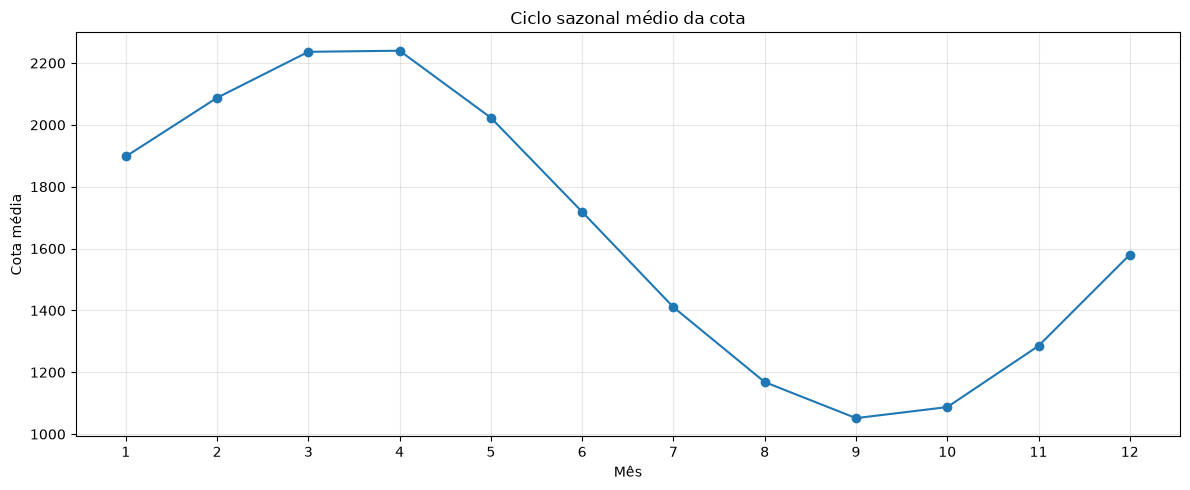

In [33]:
plt.figure(figsize=(12, 5))

plt.plot(
    media_mensal.index,
    media_mensal["mean"],
    marker="o"
)

plt.xlabel("Mês")
plt.ylabel("Cota média")
plt.title("Ciclo sazonal médio da cota")

plt.xticks(range(1, 13))

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

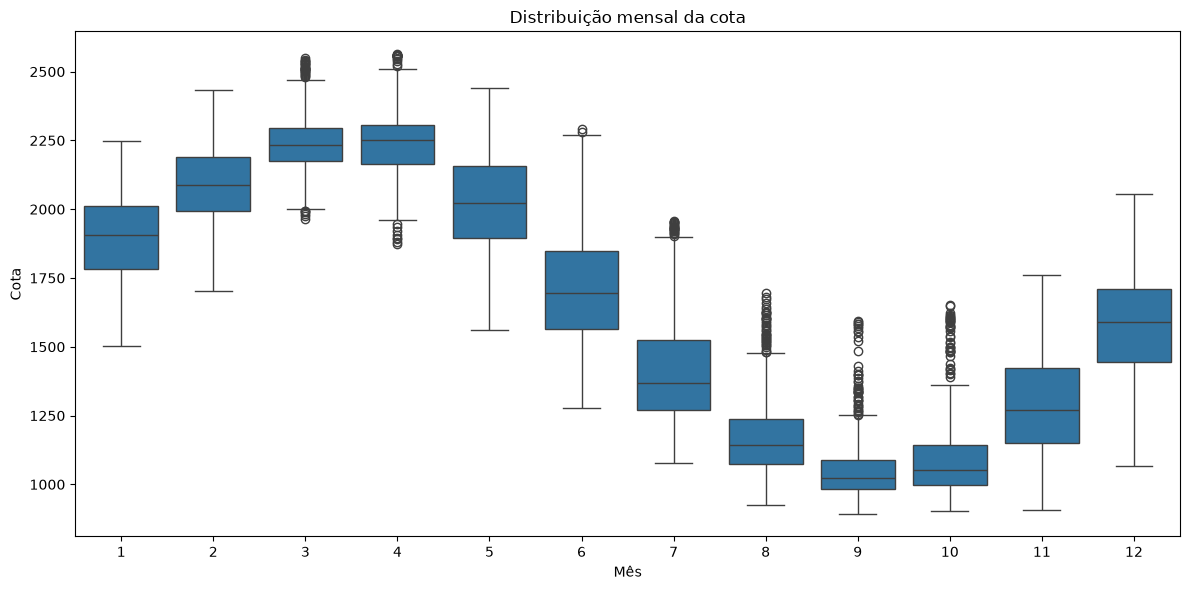

In [34]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=humaita_river_stage_data,
    x="month",
    y="river_stage"
)

plt.xlabel("Mês")
plt.ylabel("Cota")
plt.title("Distribuição mensal da cota")

plt.tight_layout()
plt.show()

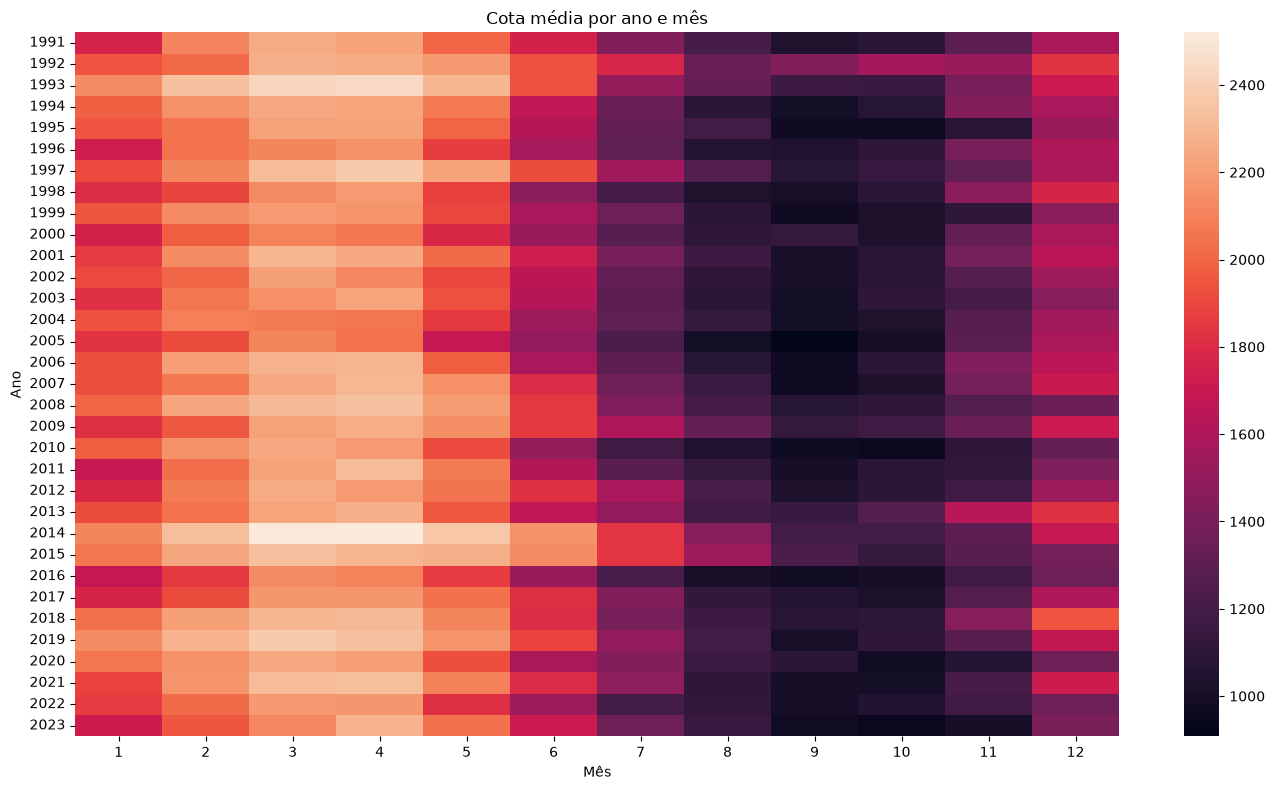

In [35]:
tabela = humaita_river_stage_data.pivot_table(
    index="year",
    columns="month",
    values="river_stage",
    aggfunc="mean"
)

plt.figure(figsize=(14, 8))

sns.heatmap(
    tabela,
    annot=False
)

plt.xlabel("Mês")
plt.ylabel("Ano")
plt.title("Cota média por ano e mês")

plt.tight_layout()
plt.show()

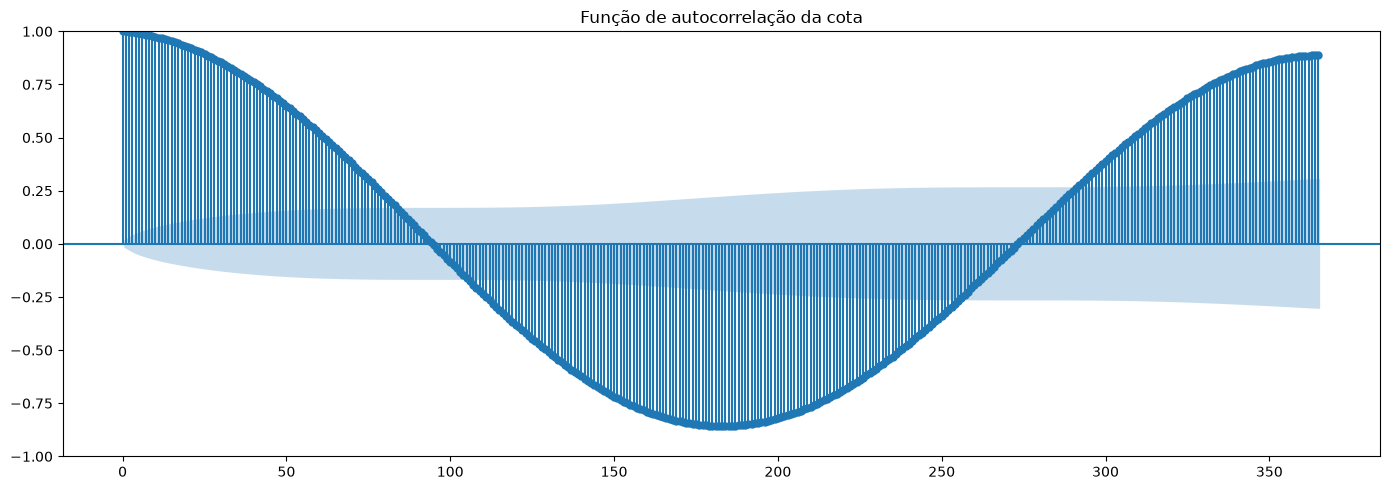

In [36]:
# ============================================
# PARTE 5 — AUTOCORRELAÇÃO
# ============================================

plt.figure(figsize=(14, 5))

plot_acf(
    humaita_river_stage_data["river_stage"],
    lags=365,
    ax=plt.gca()
)

plt.title("Função de autocorrelação da cota")

plt.tight_layout()
plt.show()

In [37]:
lags = [1, 7, 30, 90, 365]

print("\nAutocorrelação:")

for lag in lags:

    correlation = humaita_river_stage_data["river_stage"].autocorr(
        lag=lag
    )

    print(
        f"Lag {lag:>3} dias: "
        f"{correlation:.4f}"
    )


Autocorrelação:
Lag   1 dias: 0.9995
Lag   7 dias: 0.9847
Lag  30 dias: 0.8547
Lag  90 dias: 0.0719
Lag 365 dias: 0.9147


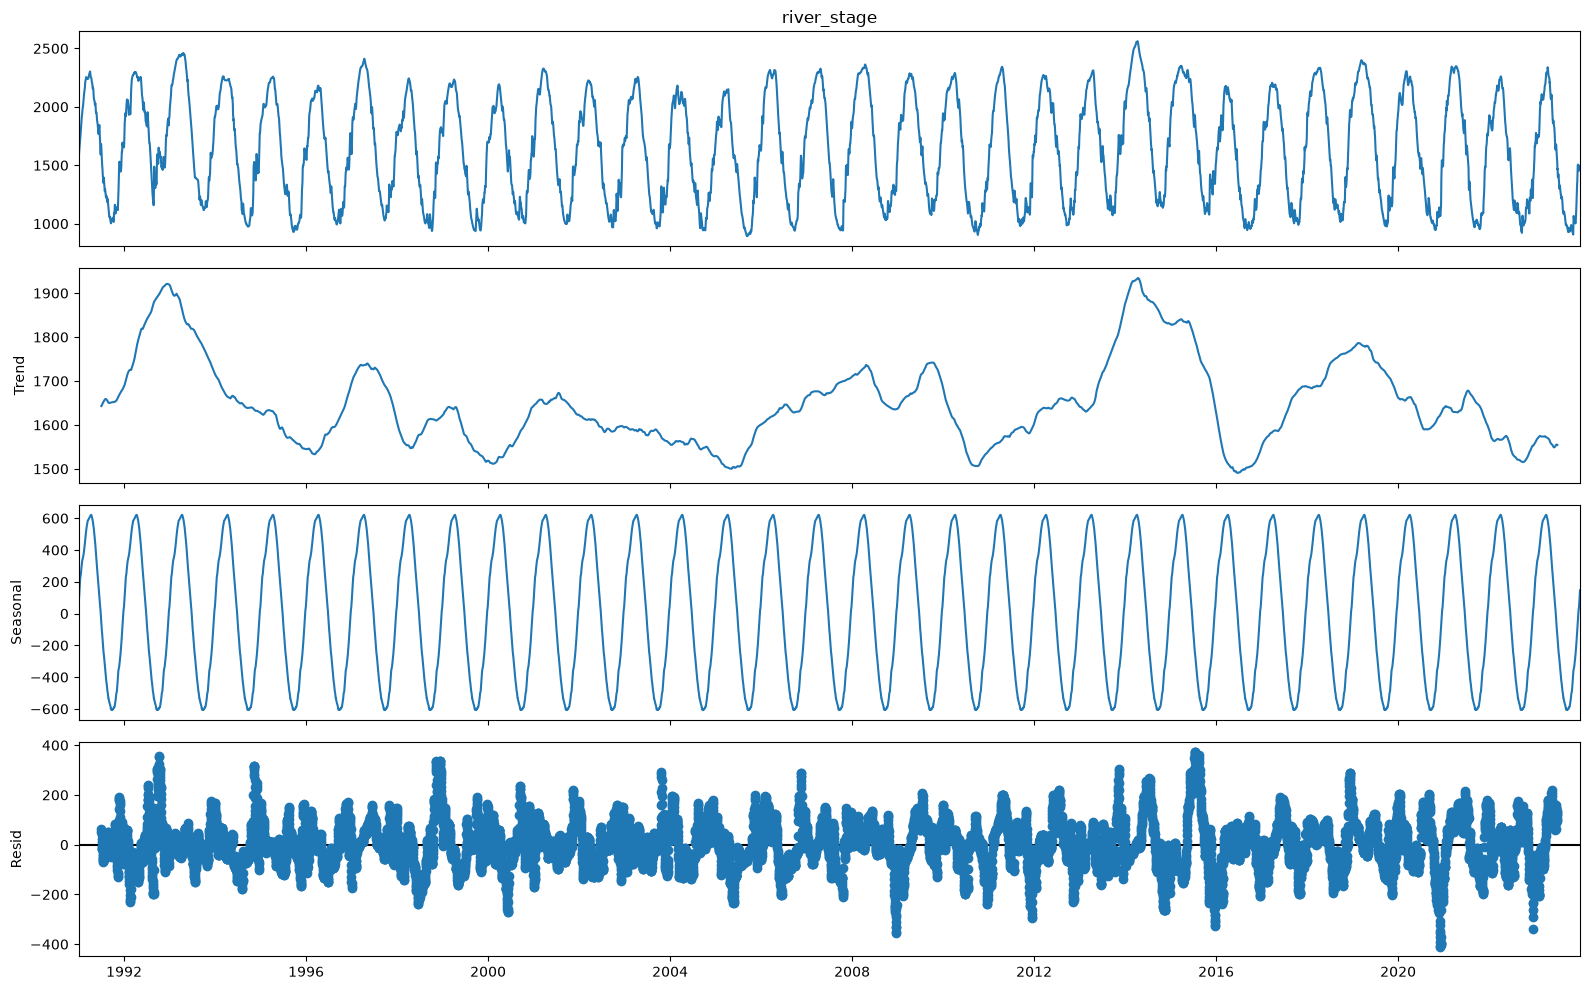

In [38]:
# ============================================
# PARTE 6 — DECOMPOSIÇÃO
# ============================================

serie = (
    humaita_river_stage_data
    .set_index("date")["river_stage"]
)

decomposicao = seasonal_decompose(
    serie,
    model="additive",
    period=365
)

fig = decomposicao.plot()
fig.set_size_inches(16, 10)

fig.tight_layout()

plt.show()

In [39]:
# ============================================
# PARTE 7 — EVENTOS EXTREMOS
# ============================================

print("=" * 60)
print("EVENTOS EXTREMOS")
print("=" * 60)


# --------------------------------------------
# QUANTIS
# --------------------------------------------

quantis = humaita_river_stage_data["river_stage"].quantile(
    [0.01, 0.05, 0.50, 0.95, 0.99]
)

print("\nQuantis:")
print(quantis)

EVENTOS EXTREMOS

Quantis:
0.01     942.00
0.05     991.00
0.50    1655.00
0.95    2302.00
0.99    2421.48
Name: river_stage, dtype: float64


In [40]:
maiores = (
    humaita_river_stage_data
    .nlargest(20, "river_stage")
    [["date", "river_stage"]]
)

print("\n20 maiores cotas:")
print(maiores)


20 maiores cotas:
           date  river_stage
8500 2014-04-10       2563.0
8499 2014-04-09       2562.0
8501 2014-04-11       2562.0
8498 2014-04-08       2560.0
8497 2014-04-07       2559.0
8502 2014-04-12       2559.0
8496 2014-04-06       2558.0
8495 2014-04-05       2557.0
8492 2014-04-02       2556.0
8494 2014-04-04       2556.0
8503 2014-04-13       2556.0
8491 2014-04-01       2555.0
8493 2014-04-03       2555.0
8490 2014-03-31       2550.0
8504 2014-04-14       2550.0
8505 2014-04-15       2547.0
8489 2014-03-30       2543.0
8488 2014-03-29       2540.0
8506 2014-04-16       2539.0
8487 2014-03-28       2538.0


In [41]:
menores = (
    humaita_river_stage_data
    .nsmallest(20, "river_stage")
    [["date", "river_stage"]]
)

print("\n20 menores cotas:")
print(menores)


20 menores cotas:
           date  river_stage
5369 2005-09-13        894.0
5370 2005-09-14        895.0
5368 2005-09-12        896.0
5363 2005-09-07        898.0
5364 2005-09-08        898.0
5362 2005-09-06        900.0
5365 2005-09-09        900.0
5367 2005-09-11        900.0
5366 2005-09-10        902.0
5371 2005-09-15        902.0
5361 2005-09-05        904.0
5375 2005-09-19        904.0
5376 2005-09-20        904.0
7218 2010-10-06        904.0
5372 2005-09-16        906.0
5373 2005-09-17        906.0
5374 2005-09-18        906.0
5377 2005-09-21        906.0
7219 2010-10-07        906.0
5360 2005-09-04        907.0


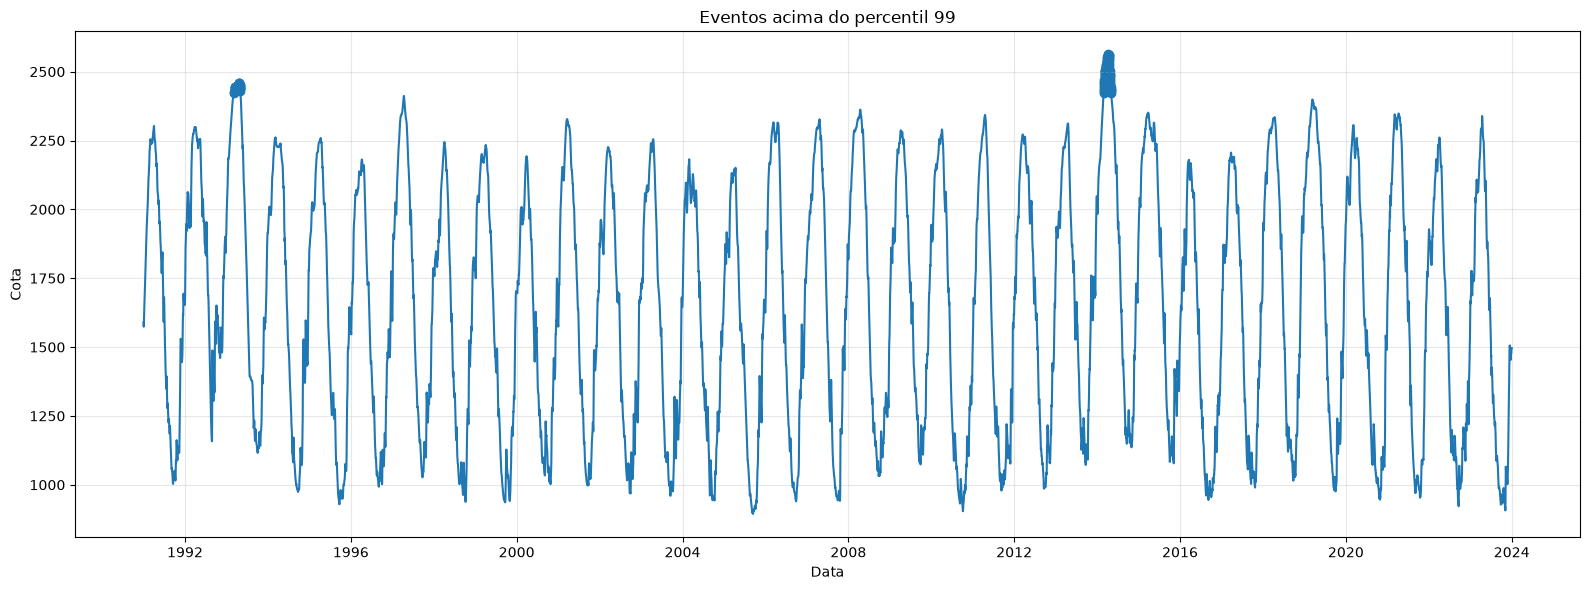

In [42]:
q99 = humaita_river_stage_data["river_stage"].quantile(0.99)

extremos = humaita_river_stage_data[
    humaita_river_stage_data["river_stage"] >= q99
]

plt.figure(figsize=(16, 6))

plt.plot(
    humaita_river_stage_data["date"],
    humaita_river_stage_data["river_stage"]
)

plt.scatter(
    extremos["date"],
    extremos["river_stage"]
)

plt.xlabel("Data")
plt.ylabel("Cota")
plt.title("Eventos acima do percentil 99")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Previsão de Cota — TimesFM 3.0

Esta seção implementa o experimento de previsão com o **TimesFM 3.0**, utilizado em configuração **zero-shot** exclusivamente com a série univariada de cota.

São avaliados os horizontes de 1, 7, 30 e 90 dias por **rolling-origin backtesting**, com origens separadas por sete dias. As métricas são MAE, RMSE e R².

O período de teste começa em **01/01/2021**. No Apple Silicon, é utilizado o backend **MLX** com o checkpoint `google/timesfm-3.0-pytorch`.


In [43]:
# ============================================
# CONFIGURAÇÃO DO EXPERIMENTO
# ============================================

TEST_START = pd.Timestamp("2021-01-01")
HORIZONS = [1, 7, 30, 90]
MAX_HORIZON = max(HORIZONS)

# Uma origem a cada 7 dias.
ORIGIN_STEP_DAYS = 7

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Período de teste:", TEST_START.date())
print("Horizontes:", HORIZONS)
print("Intervalo entre origens:", ORIGIN_STEP_DAYS, "dias")


Período de teste: 2021-01-01
Horizontes: [1, 7, 30, 90]
Intervalo entre origens: 7 dias


In [44]:
# ============================================
# VALIDAÇÃO DA SÉRIE PARA MODELAGEM
# ============================================

model_df = humaita_river_stage_data[
    ["date", "river_stage"]
].copy()

model_df["date"] = pd.to_datetime(model_df["date"])

model_df = (
    model_df
    .sort_values("date")
    .drop_duplicates("date")
    .set_index("date")
    .asfreq("D")
)

missing_dates = model_df.index[
    model_df["river_stage"].isna()
]

print("Período:", model_df.index.min().date(), "->", model_df.index.max().date())
print("Número de observações:", len(model_df))
print("Datas ausentes:", len(missing_dates))

if len(missing_dates) > 0:
    print("\nDatas ausentes:")
    print(missing_dates.strftime("%Y-%m-%d").tolist())

    raise ValueError(
        "A série ainda possui datas sem river_stage. "
        "Conclua a reconstrução dos gaps documentados "
        "antes de executar o backtesting."
    )

if model_df["river_stage"].isna().any():
    raise ValueError("Existem valores NaN em river_stage.")

print("\nSérie pronta para modelagem.")


Período: 1991-01-01 -> 2023-12-31
Número de observações: 12053
Datas ausentes: 0

Série pronta para modelagem.


In [45]:
# Série final utilizada por todos os modelos
series = model_df["river_stage"].astype(float)

# Datas disponíveis no período de teste
first_origin = TEST_START - pd.Timedelta(days=1)
last_origin = series.index.max() - pd.Timedelta(days=MAX_HORIZON)

origins = pd.date_range(
    start=first_origin,
    end=last_origin,
    freq=f"{ORIGIN_STEP_DAYS}D",
)

print("Número de origens:", len(origins))
print("Primeira origem:", origins.min().date())
print("Última origem:", origins.max().date())


Número de origens: 144
Primeira origem: 2020-12-31
Última origem: 2023-09-28


# TimesFM 3.0 — Apple Silicon / MLX

O TimesFM 3.0 será utilizado em configuração **zero-shot** e exclusivamente com `river_stage`.

A documentação oficial atual mostra:

```python
from timesfm3.mlx import TimesFM3Forecaster

forecaster = TimesFM3Forecaster.from_pretrained(
    "google/timesfm-3.0-pytorch"
)
```

e `predict` / `predict_batch` para previsão univariada. O backend MLX é próprio para Apple Silicon. Contextos acima de 15.360 pontos são truncados para os pontos mais recentes.

Neste estudo, a série de 1991–2023 possui menos de 15.360 observações, portanto o contexto histórico completo disponível até cada origem pode ser utilizado.

In [46]:
# ============================================
# CARREGAR TIMESFM 3.0 / MLX
# ============================================

from timesfm3.mlx import TimesFM3Forecaster

TIMESFM_CHECKPOINT = "google/timesfm-3.0-pytorch"
TIMESFM_MAX_CONTEXT = 15360

timesfm_model = TimesFM3Forecaster.from_pretrained(
    TIMESFM_CHECKPOINT
)

print("TimesFM 3.0 carregado.")
print("Backend: MLX")
print("Checkpoint:", TIMESFM_CHECKPOINT)


TimesFM 3.0 carregado.
Backend: MLX
Checkpoint: google/timesfm-3.0-pytorch


In [47]:
# ============================================
# BACKTESTING TIMESFM 3.0
# ============================================

timesfm_contexts = []
timesfm_metadata = []

for origin in origins:

    history = (
        series
        .loc[:origin]
        .to_numpy(dtype=np.float32)
    )

    if len(history) > TIMESFM_MAX_CONTEXT:
        history = history[-TIMESFM_MAX_CONTEXT:]

    timesfm_contexts.append(history)
    timesfm_metadata.append(origin)

# Uma única chamada em lote para todas as origens.
# Isso é mais eficiente do que carregar/executar
# o modelo separadamente para cada origem.

start_time = time.perf_counter()

outputs = list(
    timesfm_model.predict_batch(
        timesfm_contexts,
        horizon=MAX_HORIZON,
        return_quantiles=False,
        use_symmetric_averaging=False,
    )
)

total_timesfm_time = (
    time.perf_counter() - start_time
)

print(
    f"Inferências concluídas: {len(outputs)}"
)
print(
    f"Tempo total: {total_timesfm_time:.2f} s"
)


timesfm_predictions = []

for origin, output in zip(
    timesfm_metadata,
    outputs,
):

    future_dates = pd.date_range(
        start=origin + pd.Timedelta(days=1),
        periods=MAX_HORIZON,
        freq="D",
    )

    actual = series.reindex(
        future_dates
    ).to_numpy()

    if np.isnan(actual).any():
        raise ValueError(
            f"Valores ausentes após {origin.date()}."
        )

    forecast = np.asarray(
        output.forecast,
        dtype=float,
    )

    for horizon in HORIZONS:

        idx = horizon - 1

        timesfm_predictions.append({
            "model": "TimesFM 3.0",
            "origin": origin,
            "horizon": horizon,
            "target_date": future_dates[idx],
            "y_true": actual[idx],
            "y_pred": forecast[idx],
            "batch_inference_time_seconds": total_timesfm_time,
        })


timesfm_predictions_df = pd.DataFrame(
    timesfm_predictions
)

timesfm_predictions_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "timesfm3_predictions.csv",
    ),
    index=False,
)

print(
    "Previsões TimesFM:",
    len(timesfm_predictions_df)
)

timesfm_predictions_df.head()


Inferências concluídas: 144
Tempo total: 26.71 s
Previsões TimesFM: 576


,model,origin,horizon,target_date,y_true,y_pred,batch_inference_time_seconds
0,TimesFM 3.0,2020-12-31,1,2021-01-01,1668.0,1661.676392,26.706756
1,TimesFM 3.0,2020-12-31,7,2021-01-07,1776.0,1701.569946,26.706756
2,TimesFM 3.0,2020-12-31,30,2021-01-30,2014.0,1891.637817,26.706756
3,TimesFM 3.0,2020-12-31,90,2021-03-31,2335.0,2163.520752,26.706756
4,TimesFM 3.0,2021-01-07,1,2021-01-08,1783.0,1776.820435,26.706756


# Avaliação

As métricas utilizadas são **MAE**, **RMSE** e **R²**, calculadas separadamente para cada horizonte de previsão do TimesFM 3.0.


In [48]:
# ============================================
# MÉTRICAS
# ============================================

def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[mask]
    y_pred = y_pred[mask]
    return (
        mean_absolute_error(y_true, y_pred),
        np.sqrt(mean_squared_error(y_true, y_pred)),
        r2_score(y_true, y_pred),
    )


all_predictions = timesfm_predictions_df.copy()
metrics_results = []

for horizon, group in all_predictions.groupby("horizon"):
    mae, rmse, r2 = calculate_metrics(group["y_true"], group["y_pred"])
    metrics_results.append({
        "model": "TimesFM 3.0",
        "horizon": horizon,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "n_origins": group["origin"].nunique(),
    })

metrics_df = pd.DataFrame(metrics_results).sort_values("horizon").reset_index(drop=True)
metrics_df.to_csv(os.path.join(RESULTS_DIR, "metrics_summary.csv"), index=False)
metrics_df


,model,horizon,MAE,RMSE,R2,n_origins
0,TimesFM 3.0,1,6.424573,9.621054,0.999567,144
1,TimesFM 3.0,7,45.051005,57.830438,0.984571,144
2,TimesFM 3.0,30,76.831582,99.763171,0.955536,144
3,TimesFM 3.0,90,104.345567,128.196803,0.921552,144


# Resultados por horizonte

As figuras abaixo mostram MAE, RMSE e R² do TimesFM 3.0 em cada horizonte de previsão.


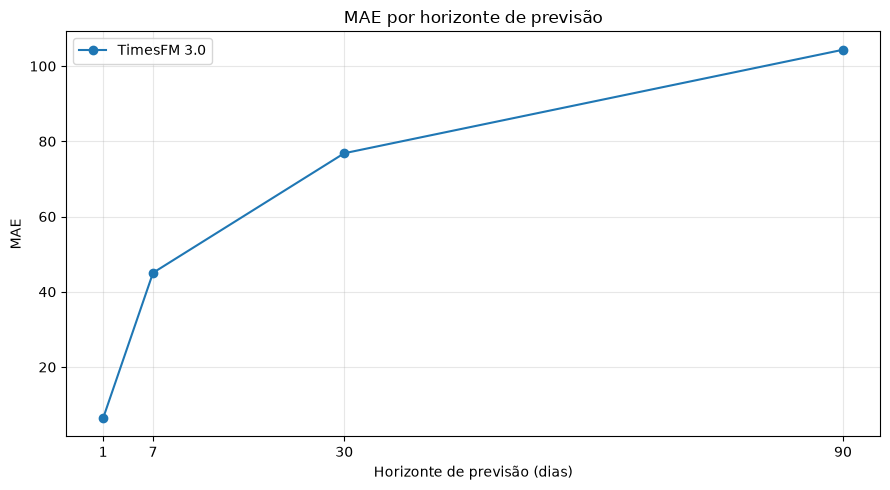

In [49]:
# ============================================
# FIGURA — MAE
# ============================================

plt.figure(figsize=(9, 5))

for model_name in metrics_df["model"].unique():

    data = (
        metrics_df[
            metrics_df["model"] == model_name
        ]
        .sort_values("horizon")
    )

    plt.plot(
        data["horizon"],
        data["MAE"],
        marker="o",
        label=model_name,
    )

plt.xlabel("Horizonte de previsão (dias)")
plt.ylabel("MAE")
plt.title("MAE por horizonte de previsão")
plt.xticks(HORIZONS)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULTS_DIR,
        "mae_vs_horizon.png",
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()


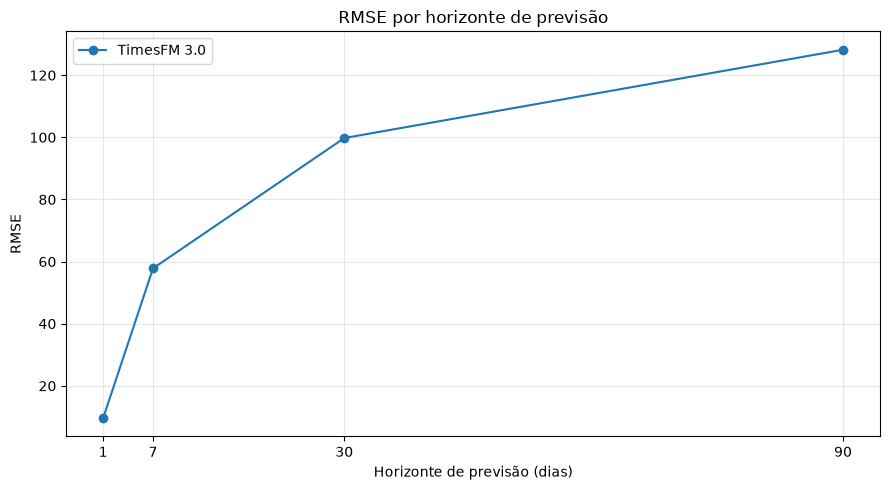

In [50]:
# ============================================
# FIGURA — RMSE
# ============================================

plt.figure(figsize=(9, 5))

for model_name in metrics_df["model"].unique():

    data = (
        metrics_df[
            metrics_df["model"] == model_name
        ]
        .sort_values("horizon")
    )

    plt.plot(
        data["horizon"],
        data["RMSE"],
        marker="o",
        label=model_name,
    )

plt.xlabel("Horizonte de previsão (dias)")
plt.ylabel("RMSE")
plt.title("RMSE por horizonte de previsão")
plt.xticks(HORIZONS)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULTS_DIR,
        "rmse_vs_horizon.png",
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()


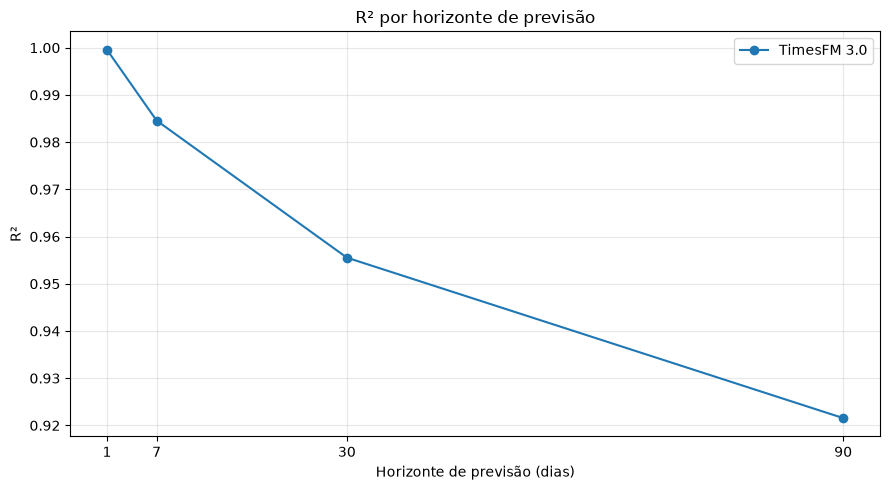

In [51]:
# ============================================
# FIGURA — R²
# ============================================

plt.figure(figsize=(9, 5))

for model_name in metrics_df["model"].unique():

    data = (
        metrics_df[
            metrics_df["model"] == model_name
        ]
        .sort_values("horizon")
    )

    plt.plot(
        data["horizon"],
        data["R2"],
        marker="o",
        label=model_name,
    )

plt.xlabel("Horizonte de previsão (dias)")
plt.ylabel("R²")
plt.title("R² por horizonte de previsão")
plt.xticks(HORIZONS)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULTS_DIR,
        "r2_vs_horizon.png",
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# Exemplo visual de previsão — 30 dias

A figura abaixo apresenta a trajetória observada e a previsão do TimesFM 3.0 para uma origem representativa do período de teste.


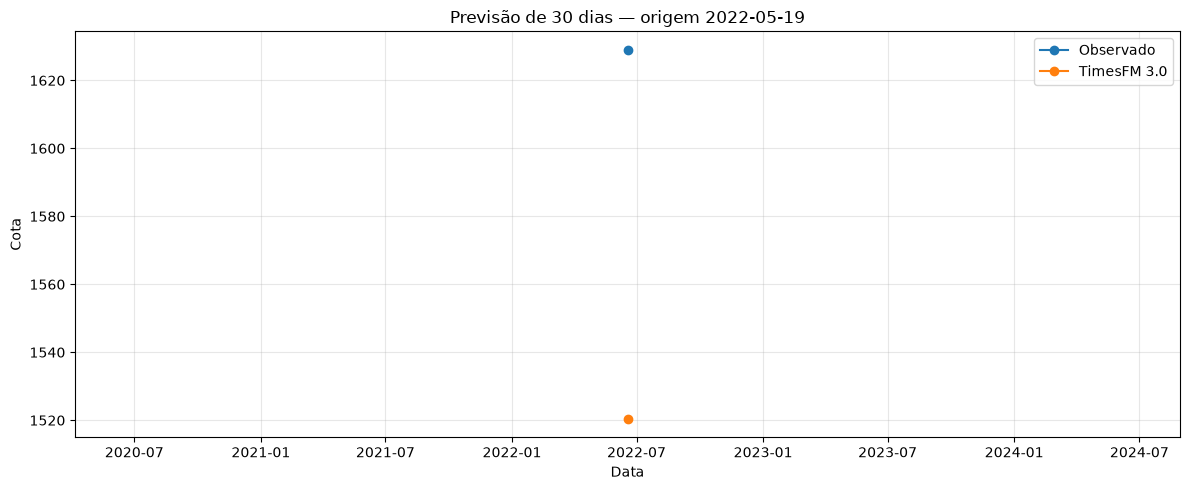

In [52]:
# ============================================
# EXEMPLO DE PREVISÃO DE 30 DIAS
# ============================================

EXAMPLE_HORIZON = 30
example = all_predictions[all_predictions["horizon"] == EXAMPLE_HORIZON].copy()
available_origins = example["origin"].drop_duplicates().sort_values()
example_origin = available_origins.iloc[len(available_origins) // 2]
example = example[example["origin"] == example_origin].sort_values("target_date")

plt.figure(figsize=(12, 5))
plt.plot(example["target_date"], example["y_true"], marker="o", label="Observado")
plt.plot(example["target_date"], example["y_pred"], marker="o", label="TimesFM 3.0")
plt.xlabel("Data")
plt.ylabel("Cota")
plt.title(f"Previsão de 30 dias — origem {example_origin.date()}")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "example_30_day_forecast.png"), dpi=300, bbox_inches="tight")
plt.show()


# Registro do ambiente

Para reprodutibilidade, registrar as versões utilizadas na execução final.

In [53]:
# ============================================
# REGISTRO DO AMBIENTE
# ============================================

environment = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "architecture": platform.machine(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "sklearn": __import__("sklearn").__version__,
}

try:
    import statsmodels
    environment["statsmodels"] = statsmodels.__version__
except Exception:
    environment["statsmodels"] = "not_available"

try:
    import timesfm
    environment["timesfm_package"] = getattr(
        timesfm,
        "__version__",
        "version_not_exposed",
    )
except Exception:
    environment["timesfm_package"] = "not_available"

environment_df = pd.DataFrame(
    list(environment.items()),
    columns=["package_or_property", "value"],
)

environment_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "environment.csv",
    ),
    index=False,
)

environment_df


,package_or_property,value
0,python,3.14.5
1,platform,macOS-26.6.2-arm64-arm-64bit-Mach-O
2,architecture,arm64
3,pandas,3.0.5
4,numpy,2.5.3
5,sklearn,1.9.1
6,statsmodels,0.15.0
7,timesfm_package,version_not_exposed


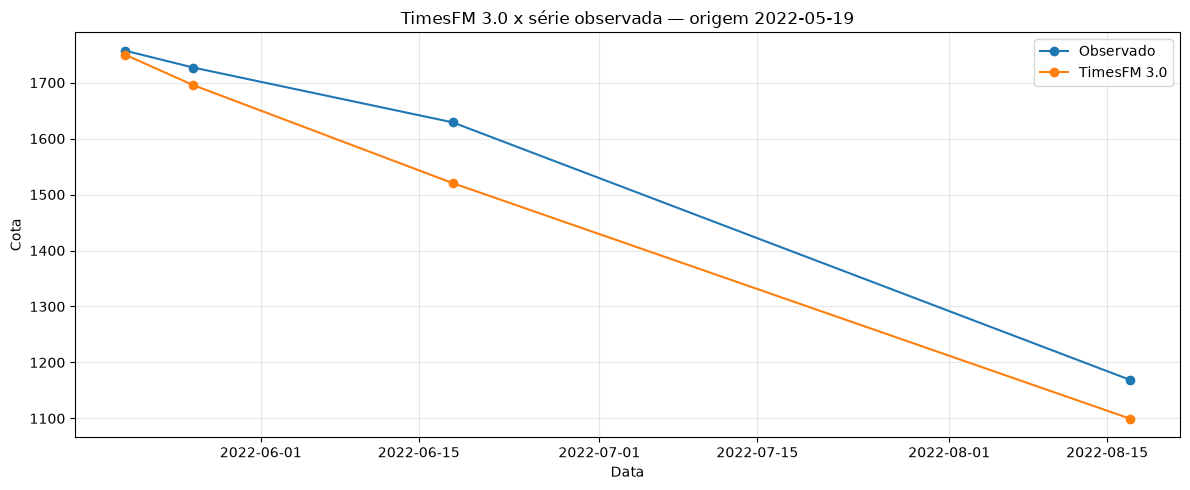

In [58]:
# ============================================
# FIGURA FINAL — TIMESFM x OBSERVADO
# ============================================

plot_data = timesfm_predictions_df.copy()

if plot_data.empty:
    raise ValueError("Não há previsões do TimesFM para plotar.")

origins_with_predictions = plot_data["origin"].drop_duplicates().sort_values()
plot_origin = origins_with_predictions.iloc[len(origins_with_predictions) // 2]
plot_data = (
    plot_data[plot_data["origin"] == plot_origin]
    .sort_values("target_date")
)

plt.figure(figsize=(12, 5))
plt.plot(
    plot_data["target_date"],
    plot_data["y_true"],
    marker="o",
    label="Observado",
)
plt.plot(
    plot_data["target_date"],
    plot_data["y_pred"],
    marker="o",
    label="TimesFM 3.0",
)
plt.xlabel("Data")
plt.ylabel("Cota")
plt.title(
    f"TimesFM 3.0 x série observada — origem {plot_origin.date()}"
)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "timesfm_vs_observed.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()
